# 9장 · 군집화 실습

가까운 중심으로 묶는 K-Means, 가까운 군집부터 합치는 계층적 군집화, 밀집한 이웃을 연결하는 DBSCAN을 비교합니다.

- PPT 오른쪽 아래의 N번호와 같은 번호를 찾으세요. 실행 횟수 `In [ ]`와는 별개입니다.
- 각 실험 셀은 필요한 import와 데이터를 다시 준비하므로 독립적으로 실행할 수 있습니다.
- PC에서는 노트북과 `data` 폴더를 같은 위치에 두세요. Colab에서는 CSV를 올리지 않아도 공개 자료를 직접 읽습니다(인터넷 필요).
- R15는 600개 점과 15개 기준 군집, Spiral은 312개 점과 3개 나선형 군집으로 구성된 합성 자료입니다. `col1`, `col2`는 좌표이고 `target`은 결과 비교용 기준 레이블입니다. `target`은 학습 입력에 넣지 않습니다.
- 그래프의 영어 축 이름은 한글 폰트 설치 없이 실행하기 위한 표기입니다.

라이브러리가 없을 때만 아래 설치 셀의 주석을 해제하세요.

In [1]:
# 준비

# %pip install numpy pandas matplotlib scipy scikit-learn
import sklearn
print("scikit-learn:", sklearn.__version__)


scikit-learn: 1.6.1


## N01 · 8개 점의 군집 배정과 중심 이동

각 점에서 세 중심까지 거리를 구하고, 가장 가까운 중심에 배정합니다. 좌표별 평균이 새 중심입니다.

In [14]:
# N01
# 데이터와 초기 중심 준비
import numpy as np
import pandas as pd

X = np.array([[2,10], [2,5], [8,4], [5,8],
              [7,5], [6,4], [1,2], [4,9]], dtype=float)

# X의 0번·3번·6번 행을 선택해 초기 중심으로 사용합니다.
centers = X[[0, 3, 6]].copy()  # A1, A4, A7
names = ["A1", "A2", "A3", "A4", "A5", "A6", "A7", "A8"]

for step in range(1, 5): # 최대 4번
    distances = np.zeros((len(X), 3))
    for k in range(3):
        distances[:, k] = np.sqrt(((X - centers[k]) ** 2).sum(axis=1))
        '''
        [2, 10] − [2, 10] = [ 0,  0]
        [2,  5] − [2, 10] = [ 0, −5]
        [8,  4] − [2, 10] = [ 6, −6]
        [5,  8] − [2, 10] = [ 3, −2]
        [7,  5] − [2, 10] = [ 5, −5]
        [6,  4] − [2, 10] = [ 4, −6]
        [1,  2] − [2, 10] = [−1, −8]
        [4,  9] − [2, 10] = [ 2, −1]
        '''
    labels = distances.argmin(axis=1) # 가장 작은 값이 있는 열 번호를 반환
    table = pd.DataFrame(distances, index=names, columns=["C1", "C2", "C3"])
    table["cluster"] = labels + 1
    print("반복", step, "거리와 배정:\n", table.round(2))
    new_centers = np.array([X[labels == k].mean(axis=0) for k in range(3)])
    print("새 중심:\n", new_centers.round(3))
    if np.allclose(centers, new_centers):
        print("중심이 더 이상 변하지 않습니다.")
        break
    centers = new_centers


반복 1 거리와 배정:
       C1    C2    C3  cluster
A1  0.00  3.61  8.06        1
A2  5.00  4.24  3.16        3
A3  8.49  5.00  7.28        2
A4  3.61  0.00  7.21        2
A5  7.07  3.61  6.71        2
A6  7.21  4.12  5.39        2
A7  8.06  7.21  0.00        3
A8  2.24  1.41  7.62        2
새 중심:
 [[ 2.  10. ]
 [ 6.   6. ]
 [ 1.5  3.5]]
반복 2 거리와 배정:
       C1    C2    C3  cluster
A1  0.00  5.66  6.52        1
A2  5.00  4.12  1.58        3
A3  8.49  2.83  6.52        2
A4  3.61  2.24  5.70        2
A5  7.07  1.41  5.70        2
A6  7.21  2.00  4.53        2
A7  8.06  6.40  1.58        3
A8  2.24  3.61  6.04        1
새 중심:
 [[3.   9.5 ]
 [6.5  5.25]
 [1.5  3.5 ]]
반복 3 거리와 배정:
       C1    C2    C3  cluster
A1  1.12  6.54  6.52        1
A2  4.61  4.51  1.58        3
A3  7.43  1.95  6.52        2
A4  2.50  3.13  5.70        1
A5  6.02  0.56  5.70        2
A6  6.26  1.35  4.53        2
A7  7.76  6.39  1.58        3
A8  1.12  4.51  6.04        1
새 중심:
 [[3.667 9.   ]
 [7.    4.333]
 [1.5   3.5  ]]
반

C1은 A1·A4·A8, C2는 A3·A5·A6, C3은 A2·A7로 수렴합니다. `argmin(axis=1)`은 각 행에서 가장 작은 거리가 있는 열 번호를 고릅니다. 중심은 점들의 평균이므로 실제 관측점과 같지 않아도 됩니다.

## N02 · KMeans로 군집과 중심 확인

fit(X)는 X의 좌표만 사용하여 군집을 학습합니다. 0·1·2는 군집 식별 번호로 크기나 순위를 뜻하지 않습니다.

In [16]:
# N02

import numpy as np
X = np.array([[2,10], [2,5], [8,4], [5,8],
              [7,5], [6,4], [1,2], [4,9]], dtype=float)

from sklearn.cluster import KMeans
model = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)

print("군집 번호:", model.labels_)
print("중심 좌표:\n", model.cluster_centers_)
print("새 점 (1, 1)의 군집:", model.predict([[1, 1]]))


군집 번호: [1 2 0 1 0 0 2 1]
중심 좌표:
 [[7.         4.33333333]
 [3.66666667 9.        ]
 [1.5        3.5       ]]
새 점 (1, 1)의 군집: [2]


### 초기 중심을 직접 지정하기

손으로 계산한 A1·A4·A7에서 시작합니다. 초기 중심을 직접 주었으므로 n_init=1로 한 번 실행합니다.

In [18]:
# N02

import numpy as np
X = np.array([[2,10], [2,5], [8,4], [5,8],
              [7,5], [6,4], [1,2], [4,9]], dtype=float)
from sklearn.cluster import KMeans
model = KMeans(n_clusters=3, init=X[[0, 3, 6]], n_init=1).fit(X)

print("군집 번호:", model.labels_)
print("중심:\n", model.cluster_centers_.round(3))


군집 번호: [0 2 1 0 1 1 2 0]
중심:
 [[3.667 9.   ]
 [7.    4.333]
 [1.5   3.5  ]]


## N03 · 군집을 색으로, 중심을 +로 표시

X[:, 0]은 x좌표, X[:, 1]은 y좌표입니다. 색이 같은 점은 같은 군집입니다.

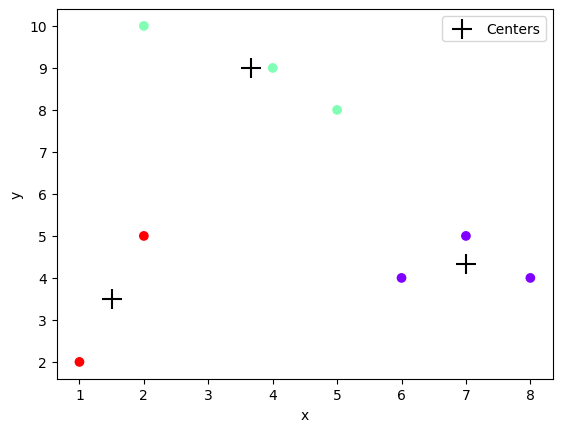

In [19]:
# N03

import numpy as np
X = np.array([[2,10], [2,5], [8,4], [5,8],
              [7,5], [6,4], [1,2], [4,9]], dtype=float)

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

model = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)

plt.scatter(X[:, 0], X[:, 1], c=model.labels_, cmap="rainbow")
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
            c="black", marker="+", s=200, label="Centers")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()


### k=2와 k=4의 결과 비교

같은 점도 지정한 군집 수에 따라 다른 묶음이 됩니다. 군집 수를 늘리는 것만으로 더 좋은 분석이라고 말할 수 없습니다.

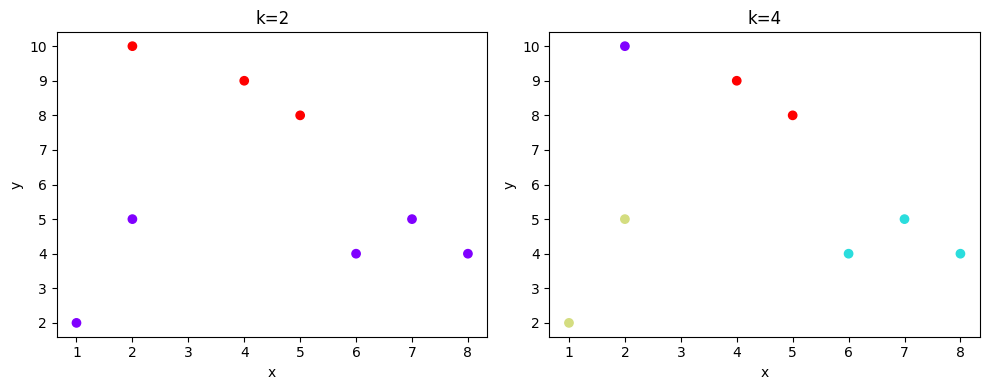

In [21]:
# N03

import numpy as np
X = np.array([[2,10], [2,5], [8,4], [5,8],
              [7,5], [6,4], [1,2], [4,9]], dtype=float)
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, k in enumerate([2, 4]):
    ax = axes[i]
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    ax.scatter(X[:, 0], X[:, 1], c=model.labels_, cmap="rainbow")
    ax.set(title=f"k={k}", xlabel="x", ylabel="y")
plt.tight_layout(); plt.show()


## N04 · R15의 15개 점 무리

좌표로 군집을 찾습니다. target은 정답을 미리 알려 주는 입력이 아니라 나중에 결과를 비교할 기준입니다.

     col1    col2
0   9.802  10.132
1  10.350   9.768
2  10.098   9.988
3   9.730   9.910
4   9.754  10.430


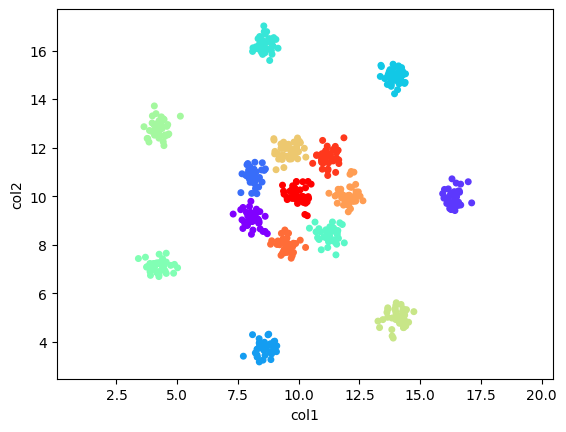

In [31]:
# N04

import pandas as pd
from pathlib import Path

path = Path("data/r15.csv")
if path.exists():
    df = pd.read_csv(path)
else:
    url = "https://raw.githubusercontent.com/milaan9/Clustering-Datasets/96df4c32d3d58746c13acf8997449aa1ae54c0e1/02.%20Synthetic/R15.arff"
    df = pd.read_csv(url, skiprows=10, header=None,
                     names=["col1", "col2", "target"])

X = df[["col1", "col2"]]
print(X.head(5))

from sklearn.cluster import KMeans
model = KMeans(n_clusters=15, random_state=42, n_init=10).fit(X)

import matplotlib.pyplot as plt
plt.scatter(X["col1"], X["col2"], c=model.labels_, cmap="rainbow", s=16)
plt.xlabel("col1"); plt.ylabel("col2"); plt.axis("equal"); plt.show()


## N05 · K-Means로 나선형 자료 묶기

색이 하나의 나선 전체를 따라가는지 확인하세요. K-Means는 중심까지의 거리로 나누므로 휘어진 군집을 잘라 버릴 수 있습니다.

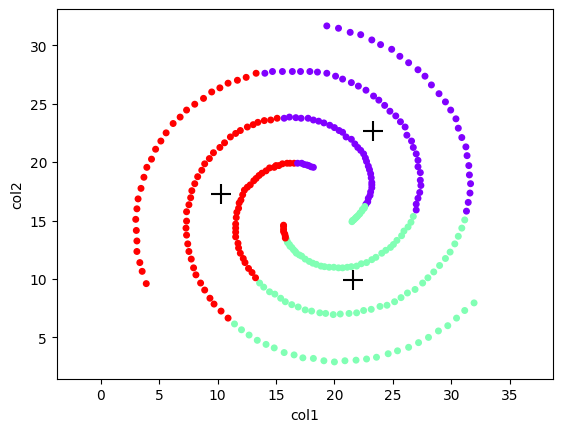

In [33]:
# N05

import pandas as pd
from pathlib import Path
# PC에서는 동봉한 CSV를, Colab에서는 공개 저장소의 같은 자료를 읽습니다.
path = Path("data/spiral.csv")
if path.exists():
    df = pd.read_csv(path)
else:
    from urllib.request import urlopen
    from io import BytesIO
    from scipy.io import loadmat
    url = "https://raw.githubusercontent.com/milaan9/Clustering-Datasets/96df4c32d3d58746c13acf8997449aa1ae54c0e1/02.%20Synthetic/spiral.mat"
    with urlopen(url, timeout=60) as response:
        mat = loadmat(BytesIO(response.read()))
    df = pd.DataFrame(mat["data"], columns=["col1", "col2"])
    df["target"] = mat["label"].ravel()
X = df[["col1", "col2"]]
from sklearn.cluster import KMeans
model = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)
import matplotlib.pyplot as plt
plt.scatter(X["col1"], X["col2"], c=model.labels_, cmap="rainbow", s=16)
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
            c="black", marker="+", s=200, label="Centers")
plt.xlabel("col1"); plt.ylabel("col2"); plt.axis("equal"); plt.show()


## N06 · 덴드로그램 읽기

평균 연결법으로 8개 점을 차례로 합칩니다. 가로축은 관측점, 세로축은 두 군집이 합쳐질 때의 연결 거리입니다.

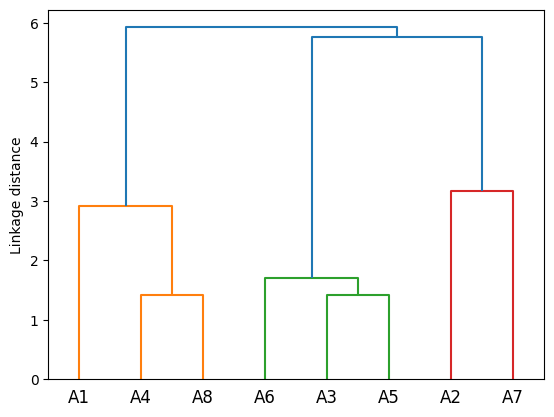

각 행: 합친 두 번호, 연결 거리, 합친 군집의 점 수
 [[ 3.     7.     1.414  2.   ]
 [ 2.     4.     1.414  2.   ]
 [ 5.     9.     1.707  3.   ]
 [ 0.     8.     2.921  3.   ]
 [ 1.     6.     3.162  2.   ]
 [10.    12.     5.763  5.   ]
 [11.    13.     5.926  8.   ]]


In [38]:
# N06

import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as shc

X = np.array([[2,10], [2,5], [8,4], [5,8],
              [7,5], [6,4], [1,2], [4,9]], dtype=float)

Z = shc.linkage(X, method="average")
shc.dendrogram(Z, labels=["A1", "A2", "A3", "A4", "A5", "A6", "A7", "A8"])
plt.ylabel("Linkage distance"); plt.show()

print("각 행: 합친 두 번호, 연결 거리, 합친 군집의 점 수\n", Z.round(3))


### 나무를 서로 다른 높이에서 자르기

threshold보다 높은 병합을 수행하지 않으면 여러 군집이 남습니다. 높이를 올릴수록 군집 수는 줄거나 그대로입니다.

In [45]:
# N06

import numpy as np
X = np.array([[2,10], [2,5], [8,4], [5,8],
              [7,5], [6,4], [1,2], [4,9]], dtype=float)
from sklearn.cluster import AgglomerativeClustering
for threshold in [2, 4, 6]:
    model = AgglomerativeClustering(n_clusters=None,
        distance_threshold=threshold, linkage="average").fit(X)
    print("높이:", threshold, "군집 수:", model.n_clusters_, "배정:", model.labels_)


높이: 2 군집 수: 5 배정: [4 3 0 2 0 0 1 2]
높이: 4 군집 수: 3 배정: [1 0 2 1 2 2 0 1]
높이: 6 군집 수: 1 배정: [0 0 0 0 0 0 0 0]


## N07 · R15에 완전 연결법 적용

complete는 두 군집 사이의 가장 먼 점 쌍으로 거리를 정합니다. n_clusters=15는 최종 군집 수입니다.

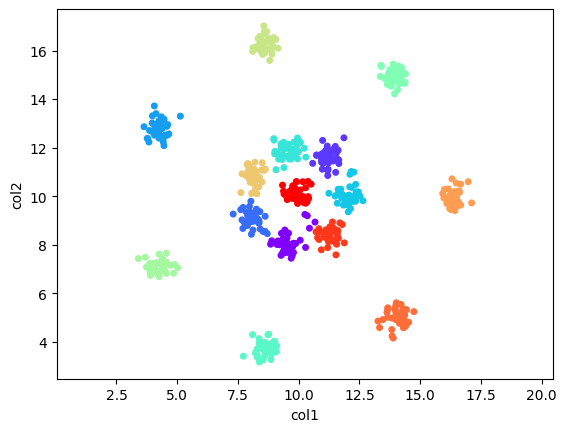

In [46]:
# N07

import pandas as pd
from pathlib import Path
# PC에서는 동봉한 CSV를, Colab에서는 공개 저장소의 같은 자료를 읽습니다.
path = Path("data/r15.csv")
if path.exists():
    df = pd.read_csv(path)
else:
    url = "https://raw.githubusercontent.com/milaan9/Clustering-Datasets/96df4c32d3d58746c13acf8997449aa1ae54c0e1/02.%20Synthetic/R15.arff"
    df = pd.read_csv(url, skiprows=10, header=None,
                     names=["col1", "col2", "target"])
X = df[["col1", "col2"]]
from sklearn.cluster import AgglomerativeClustering
model = AgglomerativeClustering(n_clusters=15, linkage="complete").fit(X)
import matplotlib.pyplot as plt
plt.scatter(X["col1"], X["col2"], c=model.labels_, cmap="rainbow", s=16)
plt.xlabel("col1"); plt.ylabel("col2"); plt.axis("equal"); plt.show()


## N08 · 나선형 자료의 연결법 비교

single·complete·average를 같은 데이터에 적용합니다. 같은 군집화 계열이라도 연결법에 따라 경계가 달라집니다.

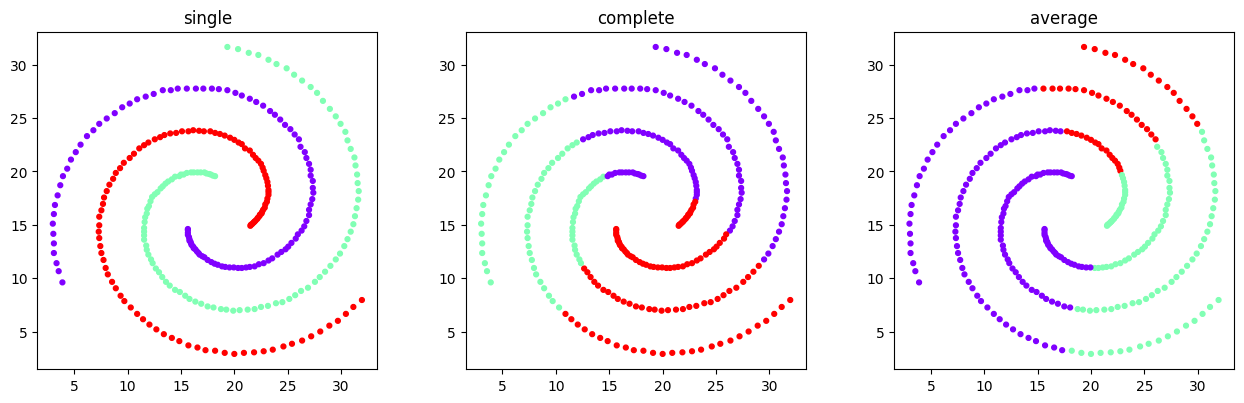

In [47]:
# N08

import pandas as pd
from pathlib import Path
# PC에서는 동봉한 CSV를, Colab에서는 공개 저장소의 같은 자료를 읽습니다.
path = Path("data/spiral.csv")
if path.exists():
    df = pd.read_csv(path)
else:
    from urllib.request import urlopen
    from io import BytesIO
    from scipy.io import loadmat
    url = "https://raw.githubusercontent.com/milaan9/Clustering-Datasets/96df4c32d3d58746c13acf8997449aa1ae54c0e1/02.%20Synthetic/spiral.mat"
    with urlopen(url, timeout=60) as response:
        mat = loadmat(BytesIO(response.read()))
    df = pd.DataFrame(mat["data"], columns=["col1", "col2"])
    df["target"] = mat["label"].ravel()
X = df[["col1", "col2"]]
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for i, method in enumerate(["single", "complete", "average"]):
    model = AgglomerativeClustering(n_clusters=3, linkage=method).fit(X)
    axes[i].scatter(X["col1"], X["col2"], c=model.labels_, cmap="rainbow", s=12)
    axes[i].set_title(method)
    axes[i].set_aspect("equal")
plt.tight_layout(); plt.show()


## N09 · R15에서 단일 연결법 사용

single은 가장 가까운 점 쌍을 기준으로 합칩니다. 중간에 놓인 점들이 다리처럼 군집을 연결하는지 관찰하세요.

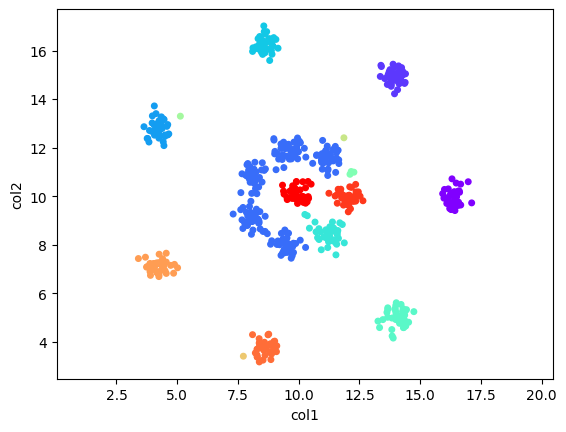

In [51]:
# N09

import pandas as pd
from pathlib import Path
# PC에서는 동봉한 CSV를, Colab에서는 공개 저장소의 같은 자료를 읽습니다.
path = Path("data/r15.csv")
if path.exists():
    df = pd.read_csv(path)
else:
    url = "https://raw.githubusercontent.com/milaan9/Clustering-Datasets/96df4c32d3d58746c13acf8997449aa1ae54c0e1/02.%20Synthetic/R15.arff"
    df = pd.read_csv(url, skiprows=10, header=None,
                     names=["col1", "col2", "target"])
X = df[["col1", "col2"]]
from sklearn.cluster import AgglomerativeClustering
model = AgglomerativeClustering(n_clusters=15, linkage="single").fit(X)
import matplotlib.pyplot as plt
plt.scatter(X["col1"], X["col2"], c=model.labels_, cmap="rainbow", s=16)
plt.xlabel("col1"); plt.ylabel("col2"); plt.axis("equal"); plt.show()


## N10 · DBSCAN과 잡음 레이블

eps는 이웃 거리, min_samples는 자기 자신을 포함한 최소 이웃 수입니다. -1은 잡음이고 군집 수에 포함하지 않습니다.

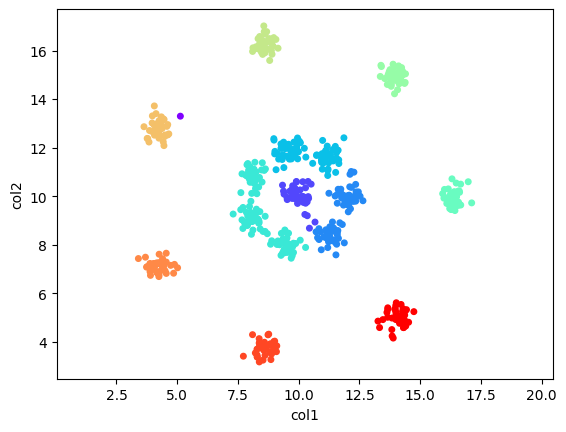

군집 수: 11
잡음 점 수: 1
-1       1
 0      42
 1      78
 2      80
 3     120
 4      40
 5      40
 6      40
 7      39
 8      40
 9      40
 10     40
Name: count, dtype: int64


In [53]:
# N10

import pandas as pd
from pathlib import Path
# PC에서는 동봉한 CSV를, Colab에서는 공개 저장소의 같은 자료를 읽습니다.
path = Path("data/r15.csv")
if path.exists():
    df = pd.read_csv(path)
else:
    url = "https://raw.githubusercontent.com/milaan9/Clustering-Datasets/96df4c32d3d58746c13acf8997449aa1ae54c0e1/02.%20Synthetic/R15.arff"
    df = pd.read_csv(url, skiprows=10, header=None,
                     names=["col1", "col2", "target"])
X = df[["col1", "col2"]]
from sklearn.cluster import DBSCAN
model = DBSCAN(eps=0.6, min_samples=10).fit(X)
import matplotlib.pyplot as plt
plt.scatter(X["col1"], X["col2"], c=model.labels_, cmap="rainbow", s=16)
plt.xlabel("col1"); plt.ylabel("col2"); plt.axis("equal"); plt.show()
labels = model.labels_
print("군집 수:", len(set(labels) - {-1}))
print("잡음 점 수:", (labels == -1).sum())
print(pd.Series(labels).value_counts().sort_index())


### eps만 바꾸었을 때

이웃 범위를 키우면 멀리 떨어진 점까지 연결할 수 있습니다. 작은 eps의 잡음과 큰 eps의 군집 합침을 비교하세요.

eps: 0.3 군집: 15 잡음: 108
eps: 0.6 군집: 11 잡음: 1
eps: 1.0 군집: 8 잡음: 0


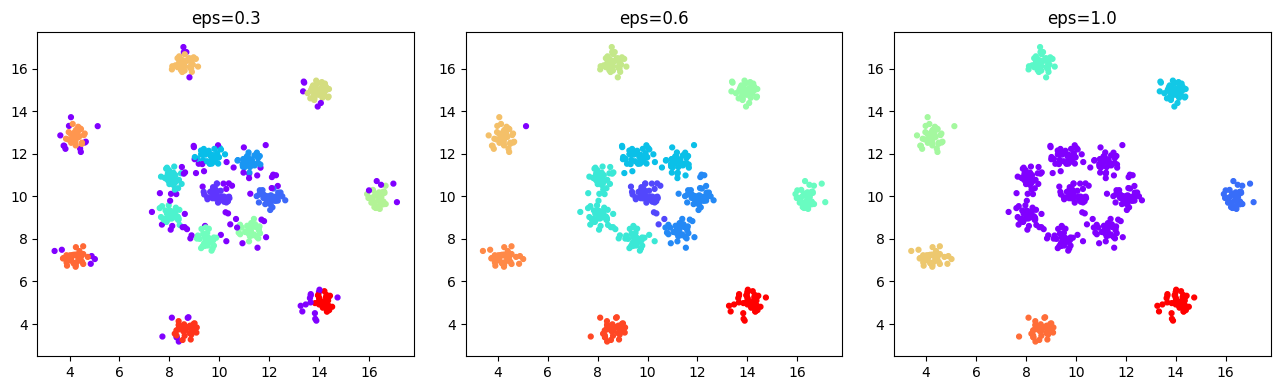

In [54]:
# N10

import pandas as pd
from pathlib import Path
# PC에서는 동봉한 CSV를, Colab에서는 공개 저장소의 같은 자료를 읽습니다.
path = Path("data/r15.csv")
if path.exists():
    df = pd.read_csv(path)
else:
    url = "https://raw.githubusercontent.com/milaan9/Clustering-Datasets/96df4c32d3d58746c13acf8997449aa1ae54c0e1/02.%20Synthetic/R15.arff"
    df = pd.read_csv(url, skiprows=10, header=None,
                     names=["col1", "col2", "target"])
X = df[["col1", "col2"]]
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for i, eps in enumerate([0.3, 0.6, 1.0]):
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
    axes[i].scatter(X["col1"], X["col2"], c=labels, cmap="rainbow", s=12)
    axes[i].set_title(f"eps={eps}")
    print("eps:", eps, "군집:", len(set(labels)-{-1}), "잡음:", (labels==-1).sum())
plt.tight_layout(); plt.show()


## N11 · DBSCAN으로 나선 따라가기

나선 모양을 알리지 않아도 가까운 이웃을 이어 군집을 찾을 수 있습니다. 좌표 간격이 달라졌으므로 R15의 eps를 그대로 쓰지 않습니다.

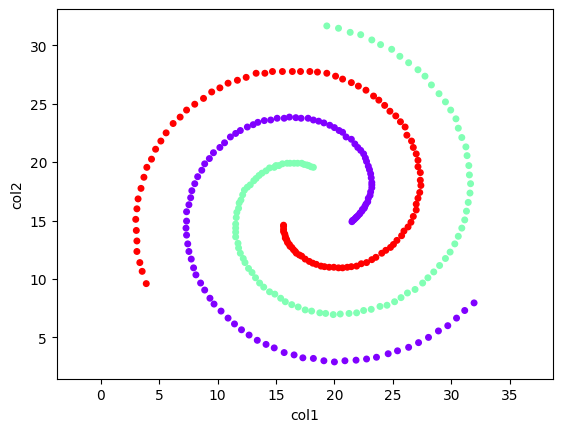

군집 수: 3
잡음 수: 0


In [55]:
# N11

import pandas as pd
from pathlib import Path
# PC에서는 동봉한 CSV를, Colab에서는 공개 저장소의 같은 자료를 읽습니다.
path = Path("data/spiral.csv")
if path.exists():
    df = pd.read_csv(path)
else:
    from urllib.request import urlopen
    from io import BytesIO
    from scipy.io import loadmat
    url = "https://raw.githubusercontent.com/milaan9/Clustering-Datasets/96df4c32d3d58746c13acf8997449aa1ae54c0e1/02.%20Synthetic/spiral.mat"
    with urlopen(url, timeout=60) as response:
        mat = loadmat(BytesIO(response.read()))
    df = pd.DataFrame(mat["data"], columns=["col1", "col2"])
    df["target"] = mat["label"].ravel()
X = df[["col1", "col2"]]
from sklearn.cluster import DBSCAN
model = DBSCAN(eps=2.0, min_samples=3).fit(X)
import matplotlib.pyplot as plt
plt.scatter(X["col1"], X["col2"], c=model.labels_, cmap="rainbow", s=16)
plt.xlabel("col1"); plt.ylabel("col2"); plt.axis("equal"); plt.show()
print("군집 수:", len(set(model.labels_) - {-1}))
print("잡음 수:", (model.labels_ == -1).sum())


## N12 · 서로 다른 밀도에서 DBSCAN 비교

교육용 합성 자료입니다. 한 집단은 조밀하고 다른 집단은 넓게 퍼져 있습니다. 하나의 eps로 두 밀도를 모두 처리하기 어려울 수 있습니다. 이 셀의 결과는 PPT의 OPTICS 비교 그림을 재현한 것은 아닙니다.

eps: 0.2 군집: 3 잡음: 108
eps: 0.8 군집: 2 잡음: 0


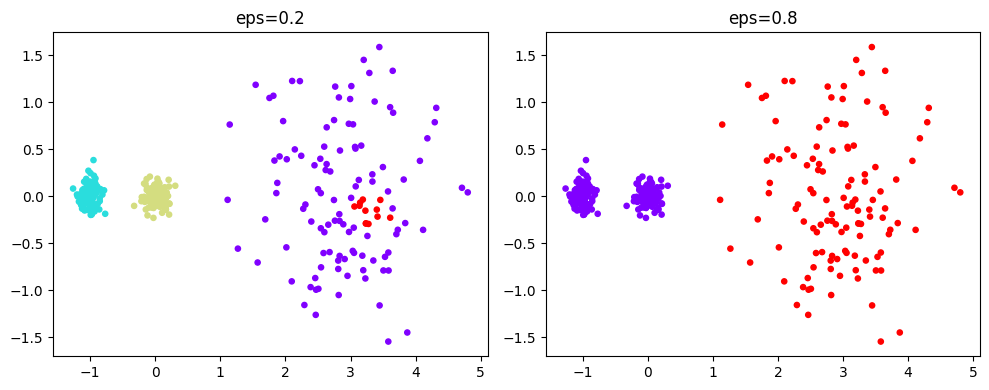

In [59]:
# N12

from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
X, target = make_blobs(n_samples=[120, 120, 120],
    centers=[[-1, 0], [0, 0], [3, 0]], cluster_std=[0.10, 0.10, 0.7], random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, eps in enumerate([0.2, 0.8]):
    labels = DBSCAN(eps=eps, min_samples=8).fit_predict(X)
    axes[i].scatter(X[:, 0], X[:, 1], c=labels, cmap="rainbow", s=14)
    axes[i].set_title(f"eps={eps}")
    print("eps:", eps, "군집:", len(set(labels)-{-1}), "잡음:", (labels==-1).sum())
plt.tight_layout(); plt.show()


## 자료 및 함수 출처

- R15·Spiral: https://github.com/milaan9/Clustering-Datasets
- scikit-learn 군집화: https://scikit-learn.org/stable/modules/clustering.html
- KMeans: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
- DBSCAN: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
- SciPy linkage: https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html
- ARI: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html


In [60]:
%pip -q install opencv-python-headless scikit-learn

import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from urllib.request import Request, urlopen

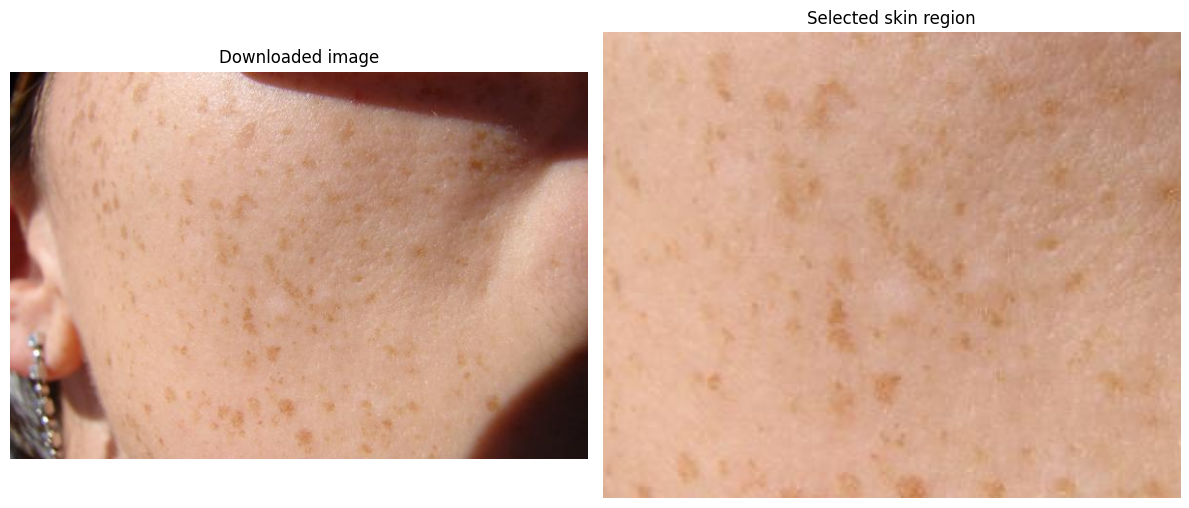

분석할 이미지의 모양: (250, 310, 3)
사진: Rei / Wikimedia Commons / CC BY 2.5


In [61]:
url = (
    "https://upload.wikimedia.org/"
    "wikipedia/commons/8/82/FrecklesCloseup.jpg"
)

request = Request(
    url,
    headers={"User-Agent": "ClusteringLectureDemo/1.0"}
)

with urlopen(request, timeout=60) as response:
    image_bytes = response.read()

# 다운로드한 파일을 OpenCV 이미지로 읽습니다.
bgr = cv2.imdecode(
    np.frombuffer(image_bytes, dtype=np.uint8),
    cv2.IMREAD_COLOR
)

if bgr is None:
    raise ValueError("이미지를 읽지 못했습니다.")

# OpenCV는 BGR, matplotlib은 RGB 순서로 색을 해석합니다.
original = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

# 이미지 슬라이싱 순서: [y 범위, x 범위]
# 이 사진에서 볼 부분에 해당하는 영역입니다.
image = original[100:350, 120:430].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(original)
axes[0].set_title("Downloaded image")

axes[1].imshow(image)
axes[1].set_title("Selected skin region")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("분석할 이미지의 모양:", image.shape)
print("사진: Rei / Wikimedia Commons / CC BY 2.5")

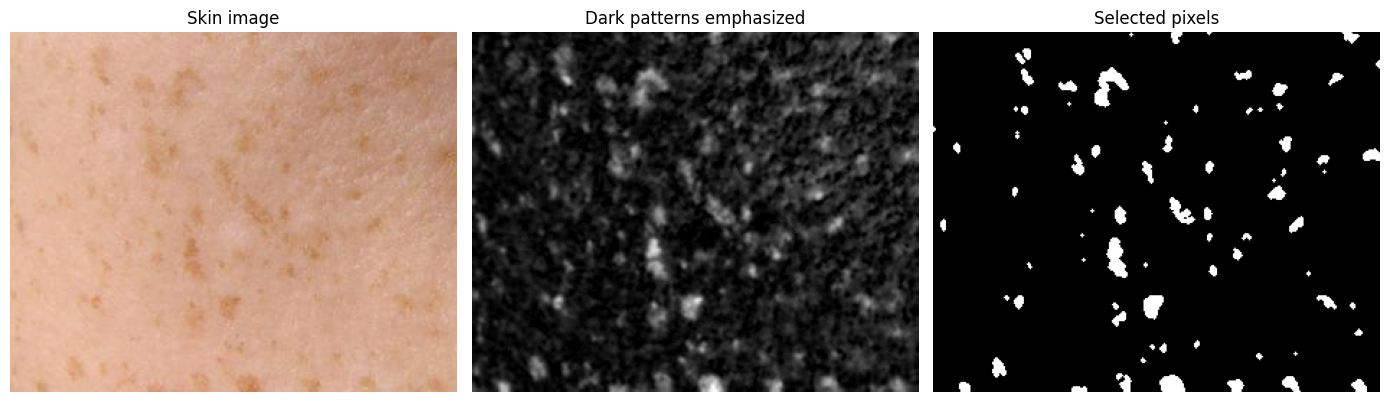

In [62]:
# 1. 색상 대신 밝기를 사용합니다.
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# 2. 작은 밝기 변화를 부드럽게 하여 잡음을 줄입니다.
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# 3. 주변보다 어두운 무늬를 강조합니다.
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (25, 25)
)

blackhat = cv2.morphologyEx(
    blurred,
    cv2.MORPH_BLACKHAT,
    kernel
)

# 4. 필터 결과가 14보다 큰 픽셀만 선택합니다.
# 14는 이 사진에 맞춰 선택한 실습용 기준입니다.
threshold_value = 14

_, mask = cv2.threshold(
    blackhat,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

# 5. 아주 작은 점이나 가느다란 잡음을 일부 제거합니다.
small_kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

mask = cv2.morphologyEx(
    mask,
    cv2.MORPH_OPEN,
    small_kernel
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(image)
axes[0].set_title("Skin image")

axes[1].imshow(blackhat, cmap="gray")
axes[1].set_title("Dark patterns emphasized")

axes[2].imshow(mask, cmap="gray")
axes[2].set_title("Selected pixels")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [63]:
# 흰색 픽셀의 행(y), 열(x) 위치를 찾습니다.
ys, xs = np.where(mask > 0)

# 각 행이 [x, y]인 좌표 배열을 만듭니다.
points = np.column_stack([xs, ys])

print("선택된 픽셀 수:", len(points))
print("처음 5개 픽셀의 [x, y] 좌표:")
print(points[:5])

if len(points) == 0:
    raise ValueError("선택된 픽셀이 없습니다. threshold_value를 낮춰보세요.")

# 좌표 단위가 픽셀이므로 eps=3은 반경 3픽셀입니다.
model = DBSCAN(
    eps=3,
    min_samples=12
)

labels = model.fit_predict(points)

# -1은 DBSCAN이 잡음으로 분류한 픽셀입니다.
cluster_ids = np.unique(labels[labels >= 0])

print("군집 수:", len(cluster_ids))
print("잡음으로 분류된 픽셀 수:", np.sum(labels == -1))

선택된 픽셀 수: 3437
처음 5개 픽셀의 [x, y] 좌표:
[[166   0]
 [167   0]
 [168   0]
 [169   0]
 [170   0]]
군집 수: 55
잡음으로 분류된 픽셀 수: 129


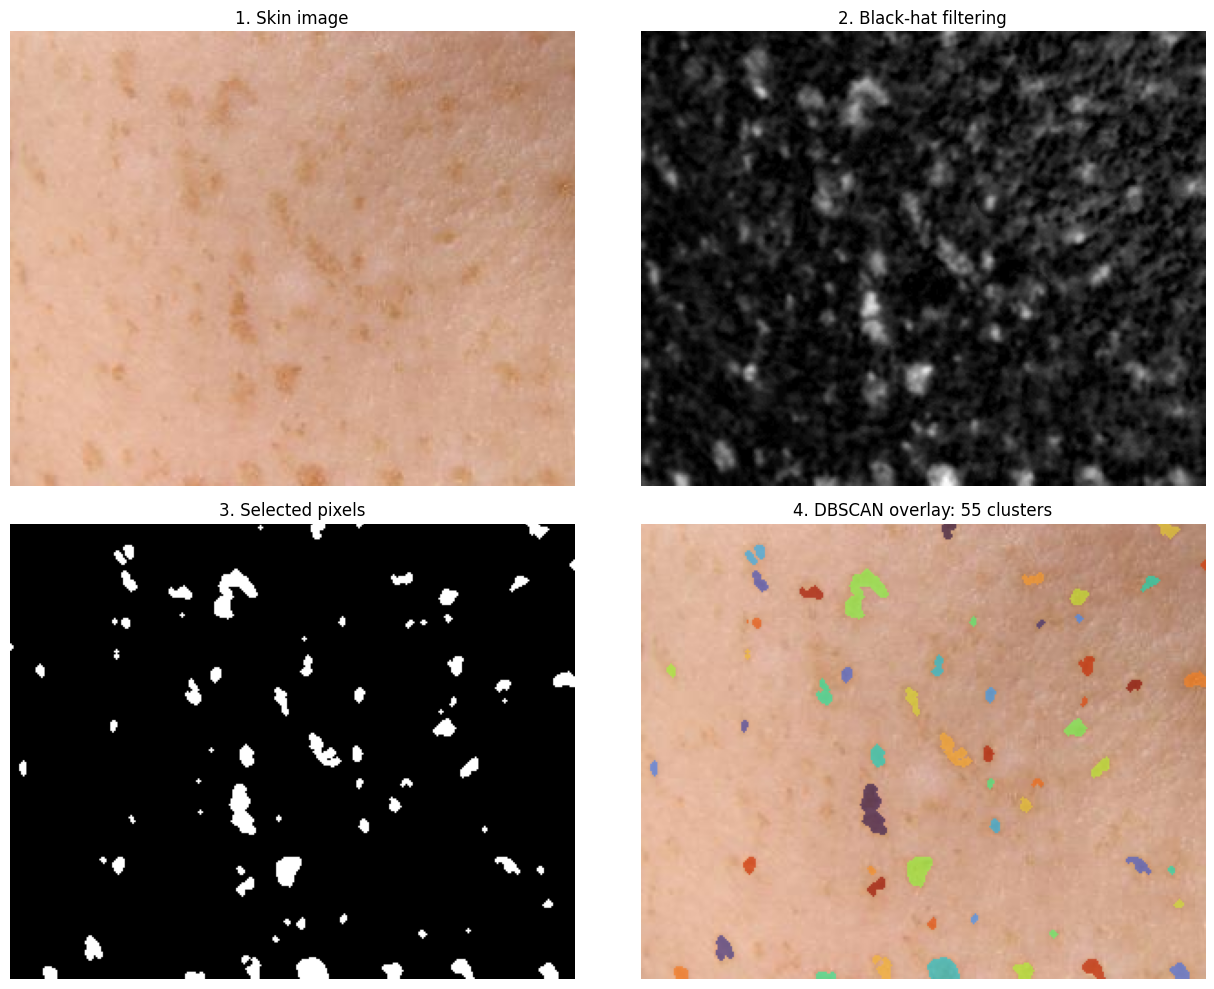

In [64]:
overlay = image.copy()

# 군집을 구분하기 위한 색상표
cmap = plt.get_cmap("turbo")

for cluster_id in cluster_ids:
    selected = labels == cluster_id

    # 해당 군집에 속하는 픽셀 좌표
    cluster_x = xs[selected]
    cluster_y = ys[selected]

    # 군집별 표시 색상
    color_position = (int(cluster_id) * 0.61803398875) % 1
    color = np.array(cmap(color_position)[:3]) * 255

    # 원본을 조금 남겨 피부 무늬와 결과를 함께 볼 수 있게 합니다.
    overlay[cluster_y, cluster_x] = (
        0.35 * image[cluster_y, cluster_x]
        + 0.65 * color
    ).astype(np.uint8)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].imshow(image)
axes[0, 0].set_title("1. Skin image")

axes[0, 1].imshow(blackhat, cmap="gray")
axes[0, 1].set_title("2. Black-hat filtering")

axes[1, 0].imshow(mask, cmap="gray")
axes[1, 0].set_title("3. Selected pixels")

axes[1, 1].imshow(overlay)
axes[1, 1].set_title(
    f"4. DBSCAN overlay: {len(cluster_ids)} clusters"
)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

# 결과 저장
plt.imsave("skin_dbscan_overlay.png", overlay)

In [65]:
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram

# 앞에서 계산한 DBSCAN 결과를 보관합니다.
dbscan_labels = labels.copy()

k = 10

if len(points) <= k:
    raise ValueError("군집 수 k를 선택된 픽셀 수보다 작게 설정하세요.")

# 1. K-means
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(points)

# 2. 응집형 계층적 군집화
# 픽셀 하나하나에서 시작하여 평균 연결법으로 군집을 합칩니다.
# Z에는 최종적으로 하나의 군집이 될 때까지의 병합 기록이 담깁니다.
Z = linkage(points, method="average")

# 병합 기록에서 군집이 k개인 단계의 결과를 가져옵니다.
hierarchical_labels = cut_tree(
    Z, n_clusters=k
).ravel()

print("DBSCAN 군집 수:",
      len(np.unique(dbscan_labels[dbscan_labels >= 0])))
print("K-means 군집 수:", len(np.unique(kmeans_labels)))
print("응집형 군집 수:", len(np.unique(hierarchical_labels)))

DBSCAN 군집 수: 55
K-means 군집 수: 10
응집형 군집 수: 10


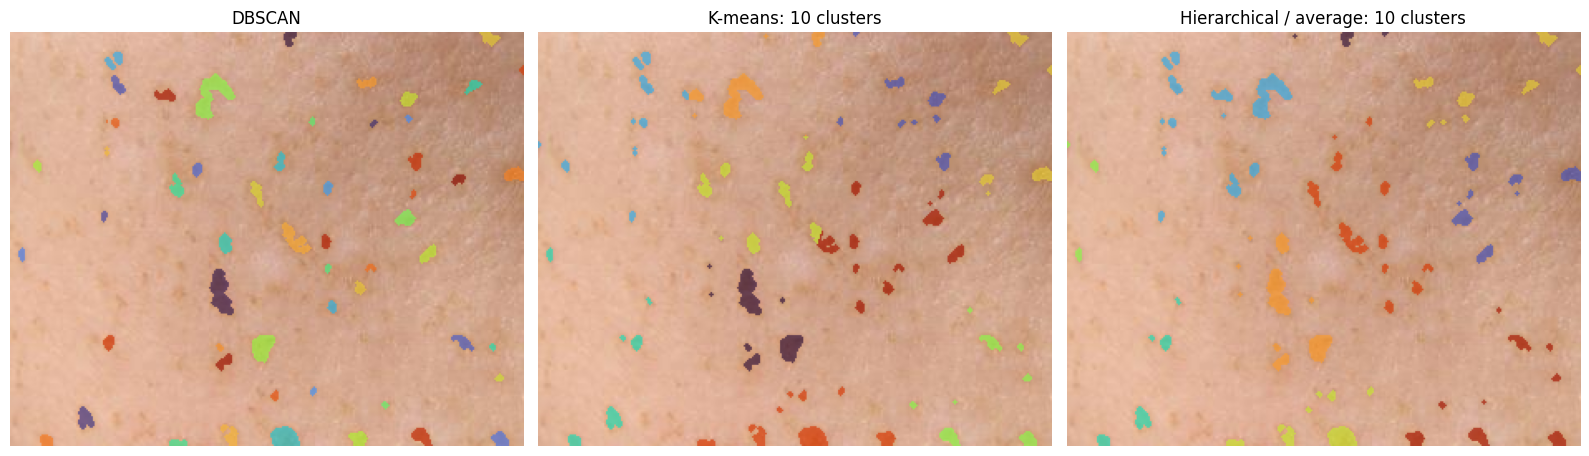

In [66]:
# 군집 번호에 따라 픽셀에 색을 입히는 함수입니다.
def make_overlay(cluster_labels):
    result = image.copy()
    cmap = plt.get_cmap("turbo")

    ids = np.unique(cluster_labels[cluster_labels >= 0])

    for cluster_id in ids:
        selected = cluster_labels == cluster_id

        cluster_x = xs[selected]
        cluster_y = ys[selected]

        color_position = (int(cluster_id) * 0.61803398875) % 1
        color = np.array(cmap(color_position)[:3]) * 255

        result[cluster_y, cluster_x] = (
            0.35 * image[cluster_y, cluster_x]
            + 0.65 * color
        ).astype(np.uint8)

    # DBSCAN의 잡음(-1)은 원본 색상 그대로 남깁니다.
    return result


dbscan_image = make_overlay(dbscan_labels)
kmeans_image = make_overlay(kmeans_labels)
hierarchical_image = make_overlay(hierarchical_labels)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(dbscan_image)
axes[0].set_title("DBSCAN")

axes[1].imshow(kmeans_image)
axes[1].set_title(f"K-means: {k} clusters")

axes[2].imshow(hierarchical_image)
axes[2].set_title(f"Hierarchical / average: {k} clusters")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()